## ANOVA
I want to know if accident rates are different between the geographic areas


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm

In [37]:
df_mun = pd.read_csv("../data/processed/municipalities_with_clusters.csv", 
                     dtype={"municipality_code": str},
                     keep_default_na=False, na_values=[""])
df_big = df_mun[df_mun["population"] >= 10000]

In the EDA the boxplot showed that the centre and the north seem to have higher accident rates than south and islans. Group means:

In [38]:
df_big.groupby("geographic_area") ["accidents_per_10k"].mean().round(2)

geographic_area
Centre        31.73
Islands       20.16
North-East    28.17
North-West    26.95
South         20.35
Name: accidents_per_10k, dtype: float64

The means are different, but it could be just chance. So I use ANOVA to check it, because I compare 5 groups.
- H0: the mean accident rate is the same in all 5 areas.
- H1: at least 1 area has a different mean.


I decide before the test. If the value is lower than 5%, I reject H0. 

In [39]:
df_big.groupby("geographic_area") ["accidents_per_10k"].agg(["mean", "std", "count"]).round(2)

,mean,std,count
geographic_area,,,
Centre,31.73,12.41,216
Islands,20.16,9.67,133
North-East,28.17,10.55,270
North-West,26.95,13.02,282
South,20.35,9.12,301


Before the ANOVA I checked the conditions.
The standard deviations are similar and the groups are large.

### The test

In [40]:
north_west = df_big[df_big["geographic_area"] == "North-West"] ["accidents_per_10k"].to_numpy()
north_east = df_big[df_big["geographic_area"] == "North-East"] ["accidents_per_10k"].to_numpy()
centre = df_big[df_big["geographic_area"] == "Centre"] ["accidents_per_10k"].to_numpy()
south = df_big[df_big["geographic_area"] == "South"] ["accidents_per_10k"].to_numpy()
islands = df_big[df_big["geographic_area"] == "Islands"] ["accidents_per_10k"].to_numpy()

f = stats.f_oneway(north_west, north_east, centre, south, islands)
print("F-statistic:", f.statistic)
print("P-value:", f.pvalue)

F-statistic: 45.747292005133374
P-value: 8.488051638611638e-36


The pvalue is much lower than 5%, so I reject H0. The accident rate is very different between the areas. Centr 32, North-East 28 (the highest rates), South and Islands 20 (the lowest). The possible reasons can be more traffic, commuting and tourism.

So the priority for the business should be given to the Centre and the North.

## Regression

I'll use a simple linear regression to forecast the number of accidents

In [41]:
df_year = pd.read_csv("../data/processed/accidents_by_municipality_year.csv", keep_default_na=False)
df_year = df_year.groupby("year") ["accidents"].sum().reset_index()
print(df_year)

    year  accidents
0   2001     254474
1   2002     256915
2   2003     244303
3   2004     235979
4   2005     232372
5   2006     229576
6   2007     222795
7   2008     211432
8   2009     207545
9   2010     210480
10  2011     203230
11  2012     185810
12  2013     179345
13  2014     175268
14  2015     172746
15  2016     174096
16  2017     174375
17  2018     172208
18  2019     172099
19  2020     118269
20  2021     151838
21  2022     165852
22  2023     166489
23  2024     173364


I'll use 2013-2024 without 2020 and 2021 (they're outliers because of COVID). Before 2013 accidents were decreasing fast, while after 2013 the trend is flat (like in EDA chart), so older years would push the forecast too low and not be realistic.

In [42]:
df_train =df_year[(df_year["year"] >= 2013) &
                  (df_year["year"].isin([2020, 2021]) == False)]
df_train

,year,accidents
12,2013,179345
13,2014,175268
14,2015,172746
15,2016,174096
16,2017,174375
17,2018,172208
18,2019,172099
21,2022,165852
22,2023,166489
23,2024,173364


Checking also other years just to be safe

In [43]:
df_train_all = df_year[(df_year["year"] >= 2001) &
                  (df_year["year"].isin([2020, 2021]) == False)]
df_train_all

,year,accidents
0,2001,254474
1,2002,256915
2,2003,244303
3,2004,235979
4,2005,232372
5,2006,229576
6,2007,222795
7,2008,211432
8,2009,207545
9,2010,210480


In [44]:
Y_all = df_train_all["accidents"]
X_all = sm.add_constant(df_train_all["year"])
results_all = sm.OLS(Y_all, X_all).fit()
print("R² with all years:", round(results_all.rsquared, 3))
print("Forecast 2025 with all years:", round(results_all.predict(np.array([[1, 2025]]))[0]))

R² with all years: 0.886
Forecast 2025 with all years: 145457


With all years (2001-2024) R² is higher (0.89), but the forecast for 2025 is about 145,000, much lower than the real value of 2024 (173,000). The line follows the fast decrease of the 2000s, which has already ended. So I use 2013-2024: R² is lower, but the forecast is more realistic. A higher R² does not always mean a better forecast.

In [45]:
Y = df_train["accidents"]
X = df_train["year"]
X = sm.add_constant(X)
model = sm.OLS(Y, X)
results = model.fit()
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              accidents   R-squared:                       0.563
Model:                            OLS   Adj. R-squared:                  0.509
Method:                 Least Squares   F-statistic:                     10.31
Date:                dom, 18 ott 2026   Prob (F-statistic):             0.0124
Time:                        00:56:18   Log-Likelihood:                -92.388
No. Observations:                  10   AIC:                             188.8
Df Residuals:                       8   BIC:                             189.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1.737e+06   4.87e+05      3.566      0.007    6.14e+05    2.86e+06
year        -775.3965    241.453     -3.211      0.012   -1332.188    -218.605
==============================================================================
Omnibus:                        1.988   Durbin-Watson:                   1.579
Prob(Omnibus):                  0.370   Jarque-Bera (JB):                0.728
Skew:                           0.660   Prob(JB):                        0.695
Kurtosis:                       2.934   Cond. No.                     1.12e+06
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.12e+06. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### Results
- No. observations = 10: the model uses 10 years (2013-2019 and 2022-2024).
- coef of year = -775: this is the slope. Every year there are about 775 fewer accidents.
- coef of const = 1,737,000: the intercept (useful for the line but alone no real meaning).
- P>|t| of year = 0.012: the p-value of the slope. The null hypothesis says that the year has no effect on accidents. The p-value is lower than 0.05, so I reject it: the decrease is real, not by chance.
- [0.025, 0.975] of year = from -1,332 to -219: the 95% confidence interval of the slope. All values are negative, so I am sure accidents are decreasing, between about 220 and 1,330 per year.
- R-squared = 0.56: the model explains about 56% of the changes in the number of accidents. The other 44% depends on other things.

In [46]:
future_years = [2025, 2026, 2027]
forecast = results.predict(np.array([[1, 2025], [1, 2026], [1, 2027]]))
for year, value in zip(future_years, forecast):
    print(year, round(value))

2025 167234
2026 166459
2027 165683


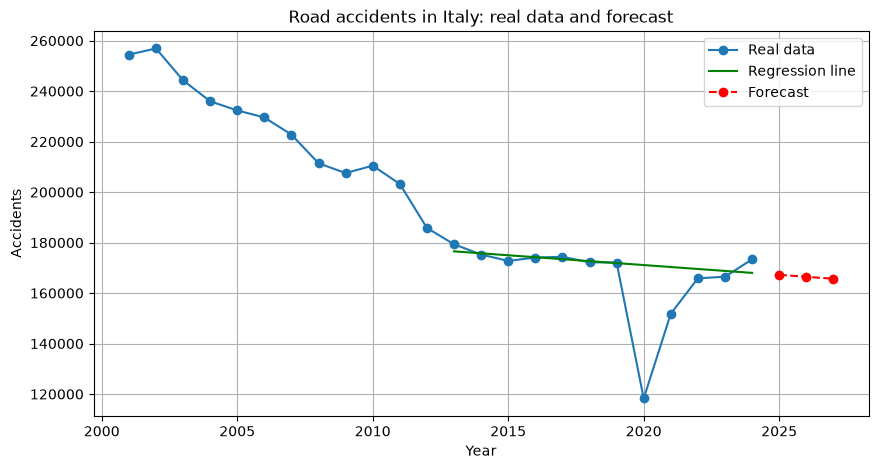

In [47]:
plt.figure(figsize=(10, 5))
plt.plot(df_year["year"], df_year["accidents"], marker="o", label="Real data")
plt.plot(df_train["year"], results.predict(X), color="green", label="Regression line")
plt.plot(future_years, forecast, marker="o", linestyle="--", color="red", label="Forecast")
plt.title("Road accidents in Italy: real data and forecast")
plt.xlabel("Year")
plt.ylabel("Accidents")
plt.legend()
plt.grid(True)
plt.show()

### What I found
The regression line shows a slight decrease of about 775 per year. The forecast is about 167,000 accidents in 2025, 166,500 in 2026 and 165,700 in 2027. In the chart, the real data stays close to the line from 2013 to 2019, while 2024 is above the line (173,000 accidents), so the recent increase goes against the trend. This means the forecast only shows the general direction (a slight decrease) and is not a precise number: the real values could also stay stable or increase, as happened in 2024.